# 02 · Diabetes Early Stage (UCI) con Keras desde cero
**Deep Learning – UCC.** Meta: **loss < 0.03** y **accuracy > 0.985**. Todos los modelos se entrenan desde cero (sin pre-entrenados).

Dataset: `data/diabetes_data_upload.csv` (520 filas, 16 variables de síntomas + `class`). Objetivo: `class` (Positive = 1, Negative = 0).
Este dataset **reemplaza al dataset Pima**, que se quedó en ~76 % de accuracy. Aquí las variables son síntomas clínicos, por lo que se espera mejorar frente al Pima, pero sin garantía de llegar a la meta. El punto crítico a vigilar son las **filas duplicadas** (fuga de datos).

Reglas que sigue el notebook:
* Los duplicados se eliminan **antes** de dividir; el resultado principal es el **sin duplicados**. El resultado "con duplicados" se muestra solo como informativo (posiblemente inflado).
* El **test no se usa para elegir nada**: se elige con validación y CV.
* Escalado y KMeans se ajustan **solo con train**.

> **Ejecutar en Google Colab:** sube la carpeta del proyecto (`data/`, `notebooks/`, `models/`, `results/`) a Colab o móntala desde Drive y ejecuta desde su raíz con `%cd /content/Momento2IA`. Colab ya trae TensorFlow; si falta algo: `!pip install -r requirements.txt`. Las rutas son relativas y funcionan igual desde `notebooks/` o desde la raíz.

## 0. Configuración
Imports agrupados, semilla fija, meta de la actividad y rutas relativas.

In [1]:
import os, gc, json, time, random, warnings
warnings.filterwarnings("ignore")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers, callbacks

from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (adjusted_rand_score, log_loss, confusion_matrix, precision_score, recall_score,
                             f1_score, classification_report, ConfusionMatrixDisplay)
from IPython.display import display

T0 = time.time()                            # para medir el tiempo total de ejecución del notebook
SEED = 42
random.seed(SEED); np.random.seed(SEED)
keras.utils.set_random_seed(SEED)          # fija random, numpy y tensorflow
tf.config.experimental.enable_op_determinism()

def limpiar():
    # libera memoria tras cada entrenamiento dentro de los bucles (cluster, búsqueda, CV, ensamble)
    keras.backend.clear_session(); gc.collect()

META_LOSS, META_ACC = 0.03, 0.985
def cumple(loss, acc): return bool(loss < META_LOSS and acc > META_ACC)

# Rutas relativas: funcionan desde notebooks/, desde la raíz del proyecto y en Colab
ROOT = ".." if os.path.basename(os.getcwd()) == "notebooks" else "."
DATA_CSV    = os.path.join(ROOT, "data", "diabetes_data_upload.csv")
MODELS_DIR  = os.path.join(ROOT, "models")
RESULTS_DIR = os.path.join(ROOT, "results")
os.makedirs(MODELS_DIR, exist_ok=True); os.makedirs(RESULTS_DIR, exist_ok=True)
assert os.path.exists(DATA_CSV), f"No se encontró {DATA_CSV}. Ejecuta desde notebooks/ o desde la raíz del proyecto."
SUF = "diabetes_early"                      # sufijo de los archivos que genera este notebook
print(f"TensorFlow {tf.__version__} | Keras {keras.__version__} | semilla {SEED}")

TensorFlow 2.21.0 | Keras 3.15.1 | semilla 42


## 1. Carga y exploración
Se normalizan los nombres de columnas (minúsculas, guion bajo, sin espacios) y se revisan forma, tipos, faltantes y balance de clases.

In [2]:
raw = pd.read_csv(DATA_CSV)
raw.columns = [c.strip().lower().replace(" ", "_") for c in raw.columns]
print("Columnas:", list(raw.columns))
print("Forma:", raw.shape, "| faltantes:", int(raw.isna().sum().sum()))
bal = raw["class"].value_counts().rename("n").to_frame(); bal["%"] = (bal.n / len(raw) * 100).round(1)
print("\nBalance de clases (con duplicados):"); display(bal)
display(raw.head(3))

Columnas: ['age', 'gender', 'polyuria', 'polydipsia', 'sudden_weight_loss', 'weakness', 'polyphagia', 'genital_thrush', 'visual_blurring', 'itching', 'irritability', 'delayed_healing', 'partial_paresis', 'muscle_stiffness', 'alopecia', 'obesity', 'class']
Forma: (520, 17) | faltantes: 0

Balance de clases (con duplicados):


,n,%
class,,
Positive,320,61.5
Negative,200,38.5


,age,gender,polyuria,polydipsia,sudden_weight_loss,weakness,polyphagia,genital_thrush,visual_blurring,itching,irritability,delayed_healing,partial_paresis,muscle_stiffness,alopecia,obesity,class
0,40,Male,No,Yes,No,Yes,No,No,No,Yes,No,Yes,No,Yes,Yes,Yes,Positive
1,58,Male,No,No,No,Yes,No,No,Yes,No,No,No,Yes,No,Yes,No,Positive
2,41,Male,Yes,No,No,Yes,Yes,No,No,Yes,No,Yes,No,Yes,Yes,No,Positive


## 2. Limpieza
* Codificación: Yes/No → 1/0, `gender` (Male=1, Female=0), `class` (Positive=1, Negative=0).
* **Duplicados (fuga de datos):** si una misma fila cae en train **y** en test, el modelo "ve" la respuesta durante el entrenamiento y la accuracy sale inflada. Se cuentan las copias exactas, se comprueba que no haya etiquetas contradictorias y se eliminan **antes de dividir**.

In [3]:
df = raw.copy()
for c in df.columns:
    if c == "age": continue
    if c == "gender":  df[c] = df[c].map({"Male": 1, "Female": 0})
    elif c == "class": df[c] = df[c].map({"Positive": 1, "Negative": 0})
    else:              df[c] = df[c].map({"Yes": 1, "No": 0})
assert df.isna().sum().sum() == 0, "Hay valores sin mapear"
df = df.astype(int)
print("Tipos tras la codificación:", df.dtypes.value_counts().to_dict())

FEATURES = [c for c in df.columns if c != "class"]
n_dup = int(df.duplicated().sum())
print(f"\nFilas duplicadas (copias de otra fila): {n_dup} de {len(df)} ({n_dup/len(df)*100:.1f}%) | filas únicas: {len(df) - n_dup}")
print("Grupos de filas idénticas con etiquetas contradictorias:", int((df.groupby(FEATURES)["class"].nunique() > 1).sum()))

df_u = df.drop_duplicates().reset_index(drop=True)          # dataset PRINCIPAL (sin duplicados)
bal_u = df_u["class"].value_counts().rename("n").to_frame(); bal_u["%"] = (bal_u.n / len(df_u) * 100).round(1)
print("\nBalance de clases (SIN duplicados):"); display(bal_u)
DUP = dict(total=len(df), duplicadas=n_dup, unicas=len(df_u))

Tipos tras la codificación: {dtype('int64'): 17}

Filas duplicadas (copias de otra fila): 269 de 520 (51.7%) | filas únicas: 251
Grupos de filas idénticas con etiquetas contradictorias: 0

Balance de clases (SIN duplicados):


,n,%
class,,
1,173,68.9
0,78,31.1


## 3. Preparación de datos (sin duplicados)
1. Partición **estratificada 70/15/15** con semilla fija.
2. Solo `age` es continua: se normaliza con `StandardScaler` **ajustado solo con train** (las demás ya son 0/1).
3. Se guarda el scaler (`models/scaler_diabetes_early.pkl`, aplica solo a `age`).
4. Se verifica que **no hay filas repetidas entre train, validación y test**.

`fit_prep` / `transform_prep` encapsulan el preprocesamiento para repetirlo **dentro de cada fold** en la validación cruzada.

In [4]:
X_all, y_all = df_u[FEATURES], df_u["class"].values
X_tr_raw, X_tmp, y_tr, y_tmp = train_test_split(X_all, y_all, test_size=0.30, stratify=y_all, random_state=SEED)
X_va_raw, X_te_raw, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
print(pd.DataFrame({"filas": [len(y_tr), len(y_va), len(y_te)], "% positivos": [y_tr.mean()*100, y_va.mean()*100, y_te.mean()*100]},
                   index=["train", "validación", "test"]).round(1))

def solape(A, B):
    return len(pd.merge(A.drop_duplicates(), B.drop_duplicates(), on=FEATURES))
print("\nFilas compartidas train∩val:", solape(X_tr_raw, X_va_raw), "| train∩test:", solape(X_tr_raw, X_te_raw), "| val∩test:", solape(X_va_raw, X_te_raw))

def fit_prep(X_raw):
    # scaler (solo age) y KMeans(k=2) ajustados SOLO con los datos recibidos (train)
    scaler = StandardScaler().fit(X_raw[["age"]])
    X = X_raw.copy(); X["age"] = scaler.transform(X_raw[["age"]]).ravel()
    km = KMeans(n_clusters=2, n_init=10, random_state=SEED).fit(X.values.astype("float32"))
    return dict(scaler=scaler, km=km)

def transform_prep(prep, X_raw, use_cluster=False):
    X = X_raw.copy(); X["age"] = prep["scaler"].transform(X_raw[["age"]]).ravel()
    A = X.values.astype("float32")
    if use_cluster: A = np.column_stack([A, prep["km"].predict(A)])
    return A.astype("float32")

prep = fit_prep(X_tr_raw)
joblib.dump(prep["scaler"], os.path.join(MODELS_DIR, f"scaler_{SUF}.pkl"))
joblib.dump(prep, os.path.join(MODELS_DIR, f"prep_{SUF}.pkl"))      # scaler + kmeans
print(f"Guardado models/scaler_{SUF}.pkl y models/prep_{SUF}.pkl")
Xtr_s, Xva_s, Xte_s = (transform_prep(prep, d) for d in (X_tr_raw, X_va_raw, X_te_raw))

            filas  % positivos
train         175         69.1
validación     38         68.4
test           38         68.4

Filas compartidas train∩val: 0 | train∩test: 0 | val∩test: 0


Guardado models/scaler_diabetes_early.pkl y models/prep_diabetes_early.pkl


## 4. Clusterización (KMeans, k=2)
KMeans se ajusta **solo con train**. Se compara con la clase real (tabla cruzada y **Adjusted Rand Index**: 1 = coinciden, ≈0 = azar). La decisión de agregar el cluster como variable se toma con evidencia en la sección 5.1.

In [5]:
km = prep["km"]
filas = []
for nombre, Xs, y in [("train", Xtr_s, y_tr), ("validación", Xva_s, y_va), ("test", Xte_s, y_te)]:
    c = km.predict(Xs)
    filas.append((nombre, adjusted_rand_score(y, c), max((c == y).mean(), (c != y).mean())))   # el id del cluster es arbitrario
print(pd.DataFrame(filas, columns=["conjunto", "ARI", "acuerdo cluster↔clase"]).set_index("conjunto").round(3))
print("\nTabla cruzada en train (filas = clase real, columnas = cluster):")
display(pd.crosstab(pd.Series(y_tr, name="clase real"), pd.Series(km.predict(Xtr_s), name="cluster")))

              ARI  acuerdo cluster↔clase
conjunto                                
train       0.070                  0.640
validación  0.020                  0.605
test       -0.014                  0.553

Tabla cruzada en train (filas = clase real, columnas = cluster):


cluster,0,1
clase real,,
0,22,32
1,80,41


## 5. Modelo
Todas con salida **sigmoide**, `binary_crossentropy`, **Adam**, **EarlyStopping** y **ReduceLROnPlateau** (sobre `val_loss`):
* **Densa:** `Dense → (BatchNorm) → Dropout`, activación configurable (relu / tanh / elu), L2.
* **Conv1D:** las variables como secuencia `(n_variables, 1)`. Son síntomas sin orden espacial real, así que la convolución no tiene ventaja natural; se prueba porque la actividad menciona CNN.

`evaluate()` calcula la entropía cruzada **pura** (Keras suma la penalización L2 en `model.evaluate`), que es la loss comparable con la meta 0.03.

In [6]:
def evaluate(model, X, y):
    p = np.clip(model.predict(X, verbose=0).ravel().astype("float64"), 1e-7, 1 - 1e-7)
    return float(log_loss(y, p, labels=[0, 1])), float(((p >= 0.5).astype(int) == y).mean())

def build_dense(n_in, units=(32, 16), act="relu", bn=False, dropout=0.2, l2=1e-3, lr=1e-3):
    reg = regularizers.l2(l2) if l2 > 0 else None
    capas = [layers.Input((n_in,))]
    for u in units:
        capas.append(layers.Dense(u, activation=act, kernel_regularizer=reg))
        if bn: capas.append(layers.BatchNormalization())
        capas.append(layers.Dropout(dropout))
    capas.append(layers.Dense(1, activation="sigmoid"))
    m = keras.Sequential(capas, name="densa")
    m.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy", metrics=["accuracy"])
    return m

def build_conv(n_in, filters=16, kernel=3, act="relu", bn=False, dropout=0.2, l2=1e-3, lr=1e-3):
    reg = regularizers.l2(l2) if l2 > 0 else None
    capas = [layers.Input((n_in,)), layers.Reshape((n_in, 1)),
             layers.Conv1D(filters, kernel, padding="same", activation=act, kernel_regularizer=reg)]
    if bn: capas.append(layers.BatchNormalization())
    capas += [layers.MaxPooling1D(2), layers.Dropout(dropout),
              layers.Conv1D(filters * 2, kernel, padding="same", activation=act, kernel_regularizer=reg),
              layers.GlobalAveragePooling1D(),
              layers.Dense(32, activation=act, kernel_regularizer=reg), layers.Dropout(dropout),
              layers.Dense(1, activation="sigmoid")]
    m = keras.Sequential(capas, name="conv1d")
    m.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy", metrics=["accuracy"])
    return m

def fit_model(model, Xtr, ytr, Xva, yva, batch=16, epochs=300, patience=25):
    cbs = [callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
           callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=8, min_lr=1e-5)]
    return model.fit(Xtr, ytr, validation_data=(Xva, yva), batch_size=batch, epochs=epochs, callbacks=cbs, verbose=0)

def build_from_cfg(c, n_in):
    if c["familia"] == "densa":
        return build_dense(n_in, c["units"], c["act"], c["bn"], c["dropout"], c["l2"], c["lr"])
    return build_conv(n_in, c["filters"], c["kernel"], c["act"], c["bn"], c["dropout"], c["l2"], c["lr"])

def describe(c):
    base = f"Dense{list(c['units'])}" if c["familia"] == "densa" else f"Conv1D[{c['filters']}x{c['kernel']}]"
    return f"{base} {c['act']}{' +BN' if c['bn'] else ''}"

def history_dict(h): return {k: [float(x) for x in v] for k, v in h.history.items()}

### 5.1 ¿Se agrega el cluster como variable? (decisión con validación)
Un modelo pequeño con 5 semillas, con y sin la columna `cluster`, comparado por **loss de validación**. Solo se adopta si la mejora supera la variabilidad entre semillas y la accuracy no empeora. KMeans es no supervisado: si coincide poco con la clase aporta ruido; si coincide mucho, la red ya aprende esa frontera con las etiquetas (redundante).

In [7]:
def quick(Xtr, Xva, n_seeds=5):
    res = []
    for s in range(n_seeds):
        keras.utils.set_random_seed(SEED + s)
        m = build_dense(Xtr.shape[1]); fit_model(m, Xtr, y_tr, Xva, y_va)
        res.append(evaluate(m, Xva, y_va)); limpiar()
    r = np.array(res); return r[:, 0], r[:, 1]

ctr, cva = km.predict(Xtr_s), km.predict(Xva_s)
l0, a0 = quick(Xtr_s, Xva_s)
l1, a1 = quick(np.column_stack([Xtr_s, ctr]).astype("float32"), np.column_stack([Xva_s, cva]).astype("float32"))
display(pd.DataFrame({"loss val (media)": [l0.mean(), l1.mean()], "loss val (std)": [l0.std(), l1.std()],
                      "acc val (media)": [a0.mean(), a1.mean()]}, index=["sin cluster", "con cluster"]).round(4))
USE_CLUSTER = bool((l0.mean() - l1.mean() > l0.std()) and (a1.mean() >= a0.mean()))
print("¿Se agrega el cluster como variable? ->", "SÍ" if USE_CLUSTER else "NO",
      f"(mejora de loss {l0.mean() - l1.mean():.4f} vs. std entre semillas {l0.std():.4f})")
Xtr, Xva, Xte = (transform_prep(prep, d, USE_CLUSTER) for d in (X_tr_raw, X_va_raw, X_te_raw))
N_IN = Xtr.shape[1]; print("Variables de entrada:", N_IN)

,loss val (media),loss val (std),acc val (media)
sin cluster,0.2953,0.0326,0.8526
con cluster,0.3015,0.0129,0.8421


¿Se agrega el cluster como variable? -> NO (mejora de loss -0.0062 vs. std entre semillas 0.0326)
Variables de entrada: 16


### 5.2 Densa vs. Conv1D (configuración inicial)
Una configuración razonable de cada familia, misma semilla, antes de la búsqueda.

In [8]:
base = {}
for nombre, builder in [("Densa", lambda: build_dense(N_IN)), ("Conv1D", lambda: build_conv(N_IN))]:
    keras.utils.set_random_seed(SEED)
    m = builder(); h = fit_model(m, Xtr, y_tr, Xva, y_va)
    (ltr, atr), (lva, ava), (lte, ate) = evaluate(m, Xtr, y_tr), evaluate(m, Xva, y_va), evaluate(m, Xte, y_te)
    base[nombre] = dict(modelo=nombre, parámetros=m.count_params(), épocas=len(h.history["loss"]),
                        loss_train=ltr, acc_train=atr, loss_val=lva, acc_val=ava, loss_test=lte, acc_test=ate)
    limpiar()
display(pd.DataFrame(base.values()).set_index("modelo").round(4))

,parámetros,épocas,loss_train,acc_train,loss_val,acc_val,loss_test,acc_test
modelo,,,,,,,,
Densa,1089,56,0.1207,0.9657,0.2327,0.8421,0.2994,0.7895
Conv1D,2721,84,0.2827,0.9086,0.3067,0.8947,0.2907,0.8684


## 6. Búsqueda de configuraciones (mejora iterativa)
Se generan con **búsqueda aleatoria** (semilla fija) 26 configuraciones candidatas sobre capas, neuronas, activación, BatchNormalization, dropout, L2, learning rate y batch size, para densa y Conv1D. **Para acortar el tiempo de ejecución se entrenan 14 de las 26** (conservan los mismos ids que en la ejecución completa anterior, así que cada una es comparable).

**Qué se conservó y qué se quitó (decisión documentada):**
* Se conservan las 3 finalistas de la ejecución completa anterior (#25, #23 y **#21 = Conv1D de 16 filtros, kernel 5, ReLU**, la ganadora) y una mezcla representativa del resto: 5 Conv1D y 9 densas, con dropout 0–0.3, L2 0–0.01, learning rate 3e-4 a 3e-3, batch 8–32, activaciones relu/elu/tanh, con y sin BatchNormalization y de 1 a 3 capas.
* Se quitan 12 configuraciones: #0, #4, #6, #7, #8, #13, #14, #15, #16, #17, #18 y #22. Ninguna de ellas estaba entre las 3 mejores por validación en la ejecución completa. El subconjunto se eligió con la validación de aquella ejecución, nunca con el test.
* Consecuencia: el espacio buscado es algo menor. Para una búsqueda exhaustiva basta con poner `KEEP = list(range(26))`.

Cada intento queda en un DataFrame con loss y accuracy en train, validación y test. ⚠️ **Las columnas de test son solo informativas.** La validación es muy pequeña (decenas de muestras), así que la selección final se desempata con validación cruzada (sección 7).

In [9]:
rng = random.Random(SEED)
configs = []
for _ in range(20):
    configs.append(dict(familia="densa", units=rng.choice([(16,), (32,), (32, 16), (64, 32), (64, 32, 16)]),
                        act=rng.choice(["relu", "tanh", "elu"]), bn=rng.choice([False, True]),
                        dropout=rng.choice([0.0, 0.1, 0.2, 0.3]), l2=rng.choice([0.0, 1e-4, 1e-3, 1e-2]),
                        lr=rng.choice([3e-4, 1e-3, 3e-3]), batch=rng.choice([8, 16, 32])))
for _ in range(6):
    configs.append(dict(familia="conv1d", filters=rng.choice([8, 16, 32]), kernel=rng.choice([3, 5]),
                        act=rng.choice(["relu", "elu"]), bn=rng.choice([False, True]),
                        dropout=rng.choice([0.1, 0.2, 0.3]), l2=rng.choice([0.0, 1e-4, 1e-3]),
                        lr=rng.choice([1e-3, 3e-3]), batch=rng.choice([8, 16, 32])))

KEEP = [1, 2, 3, 5, 9, 10, 11, 12, 19, 20, 21, 23, 24, 25]      # ids (de 0 a 25) que se entrenan; ver markdown
print(f"Configuraciones generadas: {len(configs)} | entrenadas: {len(KEEP)}")
registro, top_modelos = [], {}
for i in KEEP:
    c = configs[i]
    keras.utils.set_random_seed(SEED)
    m = build_from_cfg(c, N_IN); t0 = time.time()
    h = fit_model(m, Xtr, y_tr, Xva, y_va, batch=c["batch"])
    (ltr, atr), (lva, ava), (lte, ate) = evaluate(m, Xtr, y_tr), evaluate(m, Xva, y_va), evaluate(m, Xte, y_te)
    registro.append(dict(id=i, familia=c["familia"], arquitectura=describe(c), dropout=c["dropout"], l2=c["l2"], lr=c["lr"],
                         batch=c["batch"], épocas=len(h.history["loss"]), loss_train=ltr, acc_train=atr,
                         loss_val=lva, acc_val=ava, loss_test=lte, acc_test=ate, seg=round(time.time() - t0, 1)))
    top_modelos[i] = (m, h, lva)                       # en memoria solo los 3 mejores por loss de validación
    if len(top_modelos) > 3:
        del top_modelos[max(top_modelos, key=lambda k: top_modelos[k][2])]
    limpiar()

res = pd.DataFrame(registro)
pd.set_option("display.width", 250, "display.max_columns", 30)
display(res.sort_values("loss_val").round(4).reset_index(drop=True))
res.to_csv(os.path.join(RESULTS_DIR, f"busqueda_{SUF}.csv"), index=False)

Configuraciones generadas: 26 | entrenadas: 14


,id,familia,arquitectura,dropout,l2,lr,batch,épocas,loss_train,acc_train,loss_val,acc_val,loss_test,acc_test,seg
0,25,conv1d,Conv1D[32x5] relu,0.1,0.0000,0.0030,8,39,0.1761,0.9314,0.2347,0.9211,0.2636,0.8684,7.1
1,23,conv1d,Conv1D[32x5] relu +BN,0.3,0.0010,0.0030,8,42,0.1157,0.9657,0.2385,0.8684,0.2361,0.8947,8.3
2,21,conv1d,Conv1D[16x5] relu,0.2,0.0001,0.0010,8,78,0.1857,0.9143,0.2538,0.8947,0.3111,0.8158,12.6
3,10,densa,Dense[32] relu +BN,0.3,0.0010,0.0030,32,66,0.1205,0.9543,0.2593,0.8421,0.2331,0.8684,7.7
4,20,conv1d,Conv1D[32x3] relu +BN,0.1,0.0010,0.0010,32,87,0.1801,0.9429,0.2658,0.8684,0.3288,0.8684,10.8
5,9,densa,Dense[32] elu +BN,0.0,0.0001,0.0030,32,56,0.1674,0.9314,0.2778,0.8421,0.2411,0.9211,7.2
6,19,densa,"Dense[64, 32] relu +BN",0.1,0.0000,0.0030,16,54,0.0489,0.9829,0.2831,0.8684,0.2935,0.8684,7.6
7,24,conv1d,Conv1D[32x3] elu +BN,0.3,0.0010,0.0030,16,60,0.2162,0.9200,0.2913,0.9211,0.3548,0.8421,9.3
8,2,densa,Dense[32] relu,0.1,0.0100,0.0003,16,186,0.1752,0.9429,0.2921,0.8421,0.3037,0.8421,19.6
9,5,densa,"Dense[32, 16] tanh +BN",0.0,0.0100,0.0030,8,37,0.1819,0.9486,0.3082,0.8684,0.2574,0.8947,6.7


## 7. Validación cruzada estratificada
Se toman las **3 mejores configuraciones por loss de validación** y se desempatan con CV sobre **train + validación** (el test queda intacto). Para ahorrar tiempo, el desempate usa **5 folds × 1 repetición**; el **finalista** se completa hasta **5 folds × 3 repeticiones** (los 5 folds ya calculados + 10 más; los splits de la 1ª repetición son los mismos). En **cada fold** se vuelven a ajustar scaler y KMeans solo con la parte de entrenamiento, y un 15 % de esa parte se usa para el EarlyStopping. Gana la de menor loss de CV. Se reporta **media ± desviación**.

In [10]:
X_dev_raw = pd.concat([X_tr_raw, X_va_raw]); y_dev = np.concatenate([y_tr, y_va])
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
splits_dev = list(rskf.split(X_dev_raw, y_dev))             # 15 splits (5 folds x 3 repeticiones)
splits_busqueda = splits_dev[:5]                            # 1ª repetición = 5 folds x 1

def cv_nn(cfg, splits):
    filas = []
    for itr, iho in splits:
        Xa, Xo = X_dev_raw.iloc[itr], X_dev_raw.iloc[iho]; ya, yo = y_dev[itr], y_dev[iho]
        Xa1, Xa2, ya1, ya2 = train_test_split(Xa, ya, test_size=0.15, stratify=ya, random_state=SEED)
        p = fit_prep(Xa1)                                   # scaler y KMeans SOLO con la parte de entrenamiento del fold
        A1, A2, O = (transform_prep(p, d, USE_CLUSTER) for d in (Xa1, Xa2, Xo))
        keras.utils.set_random_seed(SEED)
        m = build_from_cfg(cfg, A1.shape[1]); fit_model(m, A1, ya1, A2, ya2, batch=cfg["batch"])
        filas.append(evaluate(m, O, yo)); limpiar()
    return np.array(filas)

def resumen_cv(f):
    return dict(loss_mean=f[:, 0].mean(), loss_std=f[:, 0].std(), acc_mean=f[:, 1].mean(), acc_std=f[:, 1].std())

top3 = res.sort_values("loss_val").head(3)["id"].tolist()
cv_busq = {}
for i in top3:
    cv_busq[i] = cv_nn(configs[i], splits_busqueda)
    r = resumen_cv(cv_busq[i])
    print(f"#{i} {describe(configs[i])}: CV 5x1 loss={r['loss_mean']:.4f}±{r['loss_std']:.4f}  acc={r['acc_mean']:.4f}±{r['acc_std']:.4f}")
best_id = min(top3, key=lambda i: cv_busq[i][:, 0].mean())
cfg_f = configs[best_id]; final, hist_final, _ = top_modelos[best_id]
print(f"\nConfiguración elegida (validación + CV, sin test): #{best_id} -> {describe(cfg_f)}  {cfg_f}")

f_full = np.vstack([cv_busq[best_id], cv_nn(cfg_f, splits_dev[5:])])      # 5x3 solo para el finalista
CV = resumen_cv(f_full)
print(f"CV 5x3 del finalista: loss={CV['loss_mean']:.4f}±{CV['loss_std']:.4f} | acc={CV['acc_mean']:.4f}±{CV['acc_std']:.4f}")

#25 Conv1D[32x5] relu: CV 5x1 loss=0.3570±0.1318  acc=0.8732±0.0565


#23 Conv1D[32x5] relu +BN: CV 5x1 loss=0.3965±0.1537  acc=0.8594±0.0702


#21 Conv1D[16x5] relu: CV 5x1 loss=0.3380±0.0906  acc=0.8640±0.0396

Configuración elegida (validación + CV, sin test): #21 -> Conv1D[16x5] relu  {'familia': 'conv1d', 'filters': 16, 'kernel': 5, 'act': 'relu', 'bn': False, 'dropout': 0.2, 'l2': 0.0001, 'lr': 0.001, 'batch': 8}


CV 5x3 del finalista: loss=0.3289±0.0674 | acc=0.8670±0.0327


### 7.1 Ensamble de 5 redes
La mejor configuración se entrena 5 veces con semillas distintas y se **promedian las probabilidades**. Es más estable; se compara con la red única por validación y CV (no se elige con test).

In [11]:
ens = []
for s in range(5):
    keras.utils.set_random_seed(SEED + 100 + s)
    m = build_from_cfg(cfg_f, N_IN); fit_model(m, Xtr, y_tr, Xva, y_va, batch=cfg_f["batch"]); ens.append(m); limpiar()

def predict_ens(X): return np.mean([m.predict(X, verbose=0).ravel() for m in ens], axis=0)
def eval_p(p, y):
    p = np.clip(p.astype("float64"), 1e-7, 1 - 1e-7)
    return float(log_loss(y, p, labels=[0, 1])), float(((p >= 0.5).astype(int) == y).mean())

ens_res = {k: eval_p(predict_ens(X), y) for k, X, y in [("train", Xtr, y_tr), ("validación", Xva, y_va), ("test", Xte, y_te)]}
print("Ensamble de 5 redes (loss, acc):", {k: (round(v[0], 4), round(v[1], 4)) for k, v in ens_res.items()})

filas = []                                  # CV del ensamble (5 redes por fold)
for itr, iho in splits_dev:
    Xa, Xo = X_dev_raw.iloc[itr], X_dev_raw.iloc[iho]; ya, yo = y_dev[itr], y_dev[iho]
    Xa1, Xa2, ya1, ya2 = train_test_split(Xa, ya, test_size=0.15, stratify=ya, random_state=SEED)
    p = fit_prep(Xa1); A1, A2, O = (transform_prep(p, d, USE_CLUSTER) for d in (Xa1, Xa2, Xo))
    ps = []
    for s in range(5):
        keras.utils.set_random_seed(SEED + 100 + s)
        m = build_from_cfg(cfg_f, A1.shape[1]); fit_model(m, A1, ya1, A2, ya2, batch=cfg_f["batch"])
        ps.append(m.predict(O, verbose=0).ravel()); limpiar()
    filas.append(eval_p(np.mean(ps, axis=0), yo))
f = np.array(filas)
CV_ENS = dict(loss_mean=f[:, 0].mean(), loss_std=f[:, 0].std(), acc_mean=f[:, 1].mean(), acc_std=f[:, 1].std())
print(f"CV ensamble: loss={CV_ENS['loss_mean']:.4f}±{CV_ENS['loss_std']:.4f} | acc={CV_ENS['acc_mean']:.4f}±{CV_ENS['acc_std']:.4f}")
print(f"CV red única: loss={CV['loss_mean']:.4f}±{CV['loss_std']:.4f} | acc={CV['acc_mean']:.4f}±{CV['acc_std']:.4f}")

Ensamble de 5 redes (loss, acc): {'train': (0.1776, 0.9486), 'validación': (0.244, 0.9211), 'test': (0.2676, 0.8158)}


CV ensamble: loss=0.3104±0.0561 | acc=0.8778±0.0415
CV red única: loss=0.3289±0.0674 | acc=0.8670±0.0327


## 8. Modelos de referencia (scikit-learn)
Regresión Logística, SVM RBF, Random Forest y Gradient Boosting con **los mismos splits** y el mismo preprocesamiento (solo `age` escalada con train), con hiperparámetros por defecto razonables (sin ajustar con test). Se reportan accuracy y `log_loss` en train, validación y test, y CV 5×3 sobre train + validación.

In [12]:
refs = {
    "Regresión Logística": lambda: LogisticRegression(max_iter=2000),
    "SVM RBF":             lambda: SVC(kernel="rbf", probability=True, random_state=SEED),
    "Random Forest":       lambda: RandomForestClassifier(n_estimators=300, random_state=SEED),
    "Gradient Boosting":   lambda: GradientBoostingClassifier(random_state=SEED),
}
def pipe(est): return make_pipeline(ColumnTransformer([("age", StandardScaler(), ["age"])], remainder="passthrough"), est)

ref_rows = []
for nombre, mk in refs.items():
    clf = mk().fit(Xtr, y_tr)
    row = {"modelo": nombre}
    for k, X, y in [("train", Xtr, y_tr), ("val", Xva, y_va), ("test", Xte, y_te)]:
        p = np.clip(clf.predict_proba(X)[:, 1], 1e-7, 1 - 1e-7)
        row[f"loss_{k}"] = log_loss(y, p, labels=[0, 1]); row[f"acc_{k}"] = ((p >= 0.5).astype(int) == y).mean()
    cvr = cross_validate(pipe(mk()), X_dev_raw, y_dev, cv=splits_dev, scoring={"acc": "accuracy", "ll": "neg_log_loss"})
    row.update(cv_loss=-cvr["test_ll"].mean(), cv_loss_std=cvr["test_ll"].std(), cv_acc=cvr["test_acc"].mean(), cv_acc_std=cvr["test_acc"].std())
    ref_rows.append(row)
ref = pd.DataFrame(ref_rows).set_index("modelo")
display(ref.round(4))
ref.to_csv(os.path.join(RESULTS_DIR, f"referencia_sklearn_{SUF}.csv"))

,loss_train,acc_train,loss_val,acc_val,loss_test,acc_test,cv_loss,cv_loss_std,cv_acc,cv_acc_std
modelo,,,,,,,,,,
Regresión Logística,0.1908,0.9257,0.3111,0.8421,0.3137,0.8421,0.2559,0.0358,0.8765,0.0272
SVM RBF,0.0475,0.9829,0.2823,0.8947,0.2911,0.8684,0.1897,0.0443,0.9280,0.0250
Random Forest,0.0656,1.0000,0.2983,0.9474,0.2895,0.8947,0.2235,0.0371,0.9233,0.0336
Gradient Boosting,0.0149,1.0000,0.5662,0.7632,0.2839,0.8684,0.2754,0.1039,0.9076,0.0497


## 9. Reporte honesto
Se reporta cada conjunto **por separado** y se indica en cuál se cumple **loss < 0.03 y accuracy > 0.985**.
* **Train:** el modelo ya vio esos datos; que sea excelente no demuestra nada (puede ser memorización).
* **Validación:** se usó para elegir y parar el entrenamiento → algo optimista.
* **Test:** única estimación imparcial, **pero con muy pocas muestras** (unas 38): cada error cuesta ~2.6 puntos de accuracy, así que acc > 0.985 exige **cero errores**.
* **CV 5×3:** la estimación más estable (train + validación; el test sigue aparte).

In [13]:
rows = {}
for nombre, X, y in [("train", Xtr, y_tr), ("validación", Xva, y_va), ("test", Xte, y_te)]:
    l, a = evaluate(final, X, y)
    rows[nombre] = dict(n=len(y), loss=l, accuracy=a, **{"loss<0.03": l < META_LOSS, "acc>0.985": a > META_ACC, "CUMPLE META": cumple(l, a)})
rows["CV 5x3 (media)"] = dict(n=len(y_dev), loss=CV["loss_mean"], accuracy=CV["acc_mean"], **{"loss<0.03": CV["loss_mean"] < META_LOSS,
                               "acc>0.985": CV["acc_mean"] > META_ACC, "CUMPLE META": cumple(CV["loss_mean"], CV["acc_mean"])})
tabla = pd.DataFrame(rows).T
display(tabla.assign(loss=tabla.loss.astype(float).round(4), accuracy=tabla.accuracy.astype(float).round(4)))
print(f"Modelo final (red única): {describe(cfg_f)} | {cfg_f}")
for k, r in rows.items():
    print(f"- {k:15s}: loss={r['loss']:.4f}, acc={r['accuracy']:.4f} -> {'CUMPLE' if r['CUMPLE META'] else 'NO cumple'} la meta")
c_tr, c_va, c_te, c_cv = (rows[k]["CUMPLE META"] for k in ("train", "validación", "test", "CV 5x3 (media)"))
if c_te and c_va and c_cv:        veredicto = "La meta SE CUMPLE en validación, test y CV."
elif c_te and c_va:               veredicto = "La meta se cumple en validación y test, pero NO en la CV (estimación más estable): resultado frágil."
elif c_tr and not (c_va or c_te): veredicto = "La meta SOLO se cumple en ENTRENAMIENTO (sobreajuste)."
elif c_te or c_va:                veredicto = f"La meta se cumple solo en {'test' if c_te else 'validación'}, no en ambos, y no en la CV."
else:                             veredicto = "La meta NO se cumple en ningún conjunto (train, validación, test ni CV)."
print("\nVEREDICTO (red única):", veredicto)
print(f"Con {len(y_te)} muestras de test, acc>0.985 exige 0 errores (1 error = {100/len(y_te):.1f} puntos).")

,n,loss,accuracy,loss<0.03,acc>0.985,CUMPLE META
train,175,0.1857,0.9143,False,False,False
validación,38,0.2538,0.8947,False,False,False
test,38,0.3111,0.8158,False,False,False
CV 5x3 (media),213,0.3289,0.8670,False,False,False


Modelo final (red única): Conv1D[16x5] relu | {'familia': 'conv1d', 'filters': 16, 'kernel': 5, 'act': 'relu', 'bn': False, 'dropout': 0.2, 'l2': 0.0001, 'lr': 0.001, 'batch': 8}
- train          : loss=0.1857, acc=0.9143 -> NO cumple la meta
- validación     : loss=0.2538, acc=0.8947 -> NO cumple la meta
- test           : loss=0.3111, acc=0.8158 -> NO cumple la meta
- CV 5x3 (media) : loss=0.3289, acc=0.8670 -> NO cumple la meta

VEREDICTO (red única): La meta NO se cumple en ningún conjunto (train, validación, test ni CV).
Con 38 muestras de test, acc>0.985 exige 0 errores (1 error = 2.6 puntos).


In [14]:
# Comparativa global: red única, ensamble y modelos de referencia (mismos splits)
l_ = {k: evaluate(final, X, y) for k, X, y in [("train", Xtr, y_tr), ("val", Xva, y_va), ("test", Xte, y_te)]}
glob = [dict(modelo="Keras red única", **{f"loss_{k}": v[0] for k, v in l_.items()}, **{f"acc_{k}": v[1] for k, v in l_.items()},
             cv_loss=CV["loss_mean"], cv_acc=CV["acc_mean"], cv_acc_std=CV["acc_std"]),
        dict(modelo="Keras ensamble x5", loss_train=ens_res["train"][0], acc_train=ens_res["train"][1], loss_val=ens_res["validación"][0],
             acc_val=ens_res["validación"][1], loss_test=ens_res["test"][0], acc_test=ens_res["test"][1],
             cv_loss=CV_ENS["loss_mean"], cv_acc=CV_ENS["acc_mean"], cv_acc_std=CV_ENS["acc_std"])]
for n, r in ref.iterrows():
    glob.append(dict(modelo=n, **{c: r[c] for c in ["loss_train", "acc_train", "loss_val", "acc_val", "loss_test", "acc_test", "cv_loss", "cv_acc", "cv_acc_std"]}))
glob = pd.DataFrame(glob).set_index("modelo")
for k, (lc, ac) in {"meta en val": ("loss_val", "acc_val"), "meta en test": ("loss_test", "acc_test"), "meta en CV": ("cv_loss", "cv_acc")}.items():
    glob[k] = [cumple(a, b) for a, b in zip(glob[lc], glob[ac])]
display(glob.round(4))
glob.to_csv(os.path.join(RESULTS_DIR, f"comparativa_modelos_{SUF}.csv"))

,loss_train,loss_val,loss_test,acc_train,acc_val,acc_test,cv_loss,cv_acc,cv_acc_std,meta en val,meta en test,meta en CV
modelo,,,,,,,,,,,,
Keras red única,0.1857,0.2538,0.3111,0.9143,0.8947,0.8158,0.3289,0.8670,0.0327,False,False,False
Keras ensamble x5,0.1776,0.2440,0.2676,0.9486,0.9211,0.8158,0.3104,0.8778,0.0415,False,False,False
Regresión Logística,0.1908,0.3111,0.3137,0.9257,0.8421,0.8421,0.2559,0.8765,0.0272,False,False,False
SVM RBF,0.0475,0.2823,0.2911,0.9829,0.8947,0.8684,0.1897,0.9280,0.0250,False,False,False
Random Forest,0.0656,0.2983,0.2895,1.0000,0.9474,0.8947,0.2235,0.9233,0.0336,False,False,False
Gradient Boosting,0.0149,0.5662,0.2839,1.0000,0.7632,0.8684,0.2754,0.9076,0.0497,False,False,False


In [15]:
# Test: matriz de confusión, precision, recall y F1 (el recall es clave: un falso negativo es un enfermo sin detectar)
p_te = (final.predict(Xte, verbose=0).ravel() >= 0.5).astype(int)
cm = confusion_matrix(y_te, p_te)
TEST_REP = dict(precision=float(precision_score(y_te, p_te)), recall=float(recall_score(y_te, p_te)), f1=float(f1_score(y_te, p_te)),
                tn=int(cm[0, 0]), fp=int(cm[0, 1]), fn=int(cm[1, 0]), tp=int(cm[1, 1]))
print(classification_report(y_te, p_te, target_names=["Negativo (0)", "Positivo (1)"], digits=4))
print(f"Falsos negativos en test: {TEST_REP['fn']} (pacientes con diabetes que el modelo NO detecta)")

              precision    recall  f1-score   support

Negativo (0)     0.6923    0.7500    0.7200        12
Positivo (1)     0.8800    0.8462    0.8627        26

    accuracy                         0.8158        38
   macro avg     0.7862    0.7981    0.7914        38
weighted avg     0.8207    0.8158    0.8177        38

Falsos negativos en test: 4 (pacientes con diabetes que el modelo NO detecta)


### Techo del dataset y limitaciones
* **Pocos datos efectivos:** al quitar los duplicados quedan ~251 pacientes únicos; train tiene ~175. Una red con miles de parámetros tiene mucha más capacidad que información.
* **Variables binarias y autorreportadas:** son 15 síntomas Sí/No más la edad. Pacientes con los mismos síntomas pueden tener diagnósticos distintos en la vida real; aquí no aparecen contradicciones, pero con tan pocos casos eso no garantiza que no existan.
* **Loss < 0.03 es muy exigente:** exige que la red esté casi siempre muy segura (p ≈ 0.99) y acierte; un solo error confiado en 38 pacientes ya lo rompe. Con pocos datos, la regularización necesaria para generalizar impide esa confianza.
* **Modelos de referencia:** comparar la red con SVM, Random Forest y Gradient Boosting (tabla de arriba) indica si el límite está en los datos o en la arquitectura.
* **Limitaciones:** dataset pequeño (520 filas, 251 únicas), recogido en **un solo hospital** (Sylhet, Bangladesh) con **variables autorreportadas** (síntomas dichos por el paciente, no mediciones de laboratorio; no hay glucosa ni HbA1c). Los resultados no se pueden extrapolar a otras poblaciones y **esto no es una herramienta de diagnóstico**.

### 9.1 Resultado "con duplicados" (SOLO INFORMATIVO — puede estar inflado)
Se repite el flujo sobre las 520 filas **sin quitar duplicados**: misma partición 70/15/15, la configuración elegida y un Random Forest. Se mide cuántas filas del test tienen una **copia exacta en train** (fuga). Estas cifras **no son resultados válidos**: muestran cuánto se infla la métrica cuando hay fuga.

In [16]:
Xd, yd = df[FEATURES], df["class"].values
Xd_tr, Xd_tmp, yd_tr, yd_tmp = train_test_split(Xd, yd, test_size=0.30, stratify=yd, random_state=SEED)
Xd_va, Xd_te, yd_va, yd_te = train_test_split(Xd_tmp, yd_tmp, test_size=0.50, stratify=yd_tmp, random_state=SEED)
prep_d = fit_prep(Xd_tr)
D = [transform_prep(prep_d, d, USE_CLUSTER) for d in (Xd_tr, Xd_va, Xd_te)]
claves_tr = set(map(tuple, Xd_tr.values))
fuga_te = np.mean([tuple(r) in claves_tr for r in Xd_te.values]); fuga_va = np.mean([tuple(r) in claves_tr for r in Xd_va.values])
print(f"Filas del test con copia exacta en train: {fuga_te*100:.1f}% | validación: {fuga_va*100:.1f}%")

keras.utils.set_random_seed(SEED)
m_dup = build_from_cfg(cfg_f, D[0].shape[1]); fit_model(m_dup, D[0], yd_tr, D[1], yd_va, batch=cfg_f["batch"]); limpiar()
l_d, a_d = evaluate(m_dup, D[2], yd_te)
rf_d = RandomForestClassifier(n_estimators=300, random_state=SEED).fit(D[0], yd_tr)
p_rf = np.clip(rf_d.predict_proba(D[2])[:, 1], 1e-7, 1 - 1e-7)
l_rf, a_rf = log_loss(yd_te, p_rf, labels=[0, 1]), ((p_rf >= 0.5).astype(int) == yd_te).mean()
CON_DUP = pd.DataFrame({"loss test": [l_d, l_rf], "acc test": [a_d, a_rf], "¿cumple meta?": [cumple(l_d, a_d), cumple(l_rf, a_rf)]},
                       index=["Keras (misma config)", "Random Forest"]).round(4)
display(CON_DUP)
print("⚠️ CON DUPLICADOS = resultado INFLADO por fuga de datos (informativo). El resultado honesto es el de datos sin duplicados.")

Filas del test con copia exacta en train: 61.5% | validación: 74.4%


,loss test,acc test,¿cumple meta?
Keras (misma config),0.1595,0.9359,False
Random Forest,0.0836,0.9872,False


⚠️ CON DUPLICADOS = resultado INFLADO por fuga de datos (informativo). El resultado honesto es el de datos sin duplicados.


## 10. Gráficas
Loss y accuracy de entrenamiento vs. validación por época (la loss de Keras incluye la penalización L2) y matriz de confusión en test.

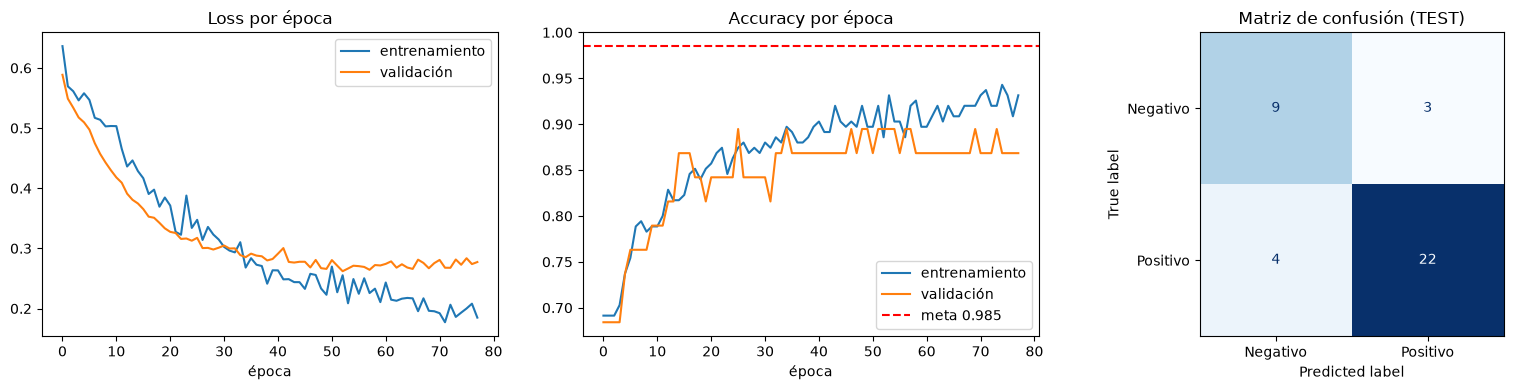

In [17]:
h = hist_final.history
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(h["loss"], label="entrenamiento"); ax[0].plot(h["val_loss"], label="validación")
ax[0].set_title("Loss por época"); ax[0].set_xlabel("época"); ax[0].legend()
ax[1].plot(h["accuracy"], label="entrenamiento"); ax[1].plot(h["val_accuracy"], label="validación")
ax[1].axhline(META_ACC, color="r", ls="--", label="meta 0.985"); ax[1].set_title("Accuracy por época"); ax[1].set_xlabel("época"); ax[1].legend()
ConfusionMatrixDisplay(cm, display_labels=["Negativo", "Positivo"]).plot(ax=ax[2], colorbar=False, cmap="Blues")
ax[2].set_title("Matriz de confusión (TEST)")
plt.tight_layout(); plt.show()

## 11. Guardado
En `models/` y `results/`: el modelo `.keras`, el historial de entrenamiento (`.json` y `.csv`, para graficar después) y un resumen de resultados (`resultados_diabetes_early.json`). El scaler, la tabla de búsqueda y las comparativas ya se guardaron antes.

In [18]:
final.save(os.path.join(MODELS_DIR, f"model_{SUF}.keras"))
hd = history_dict(hist_final)
json.dump(hd, open(os.path.join(RESULTS_DIR, f"history_{SUF}.json"), "w"), indent=1)
pd.DataFrame(hd).to_csv(os.path.join(RESULTS_DIR, f"history_{SUF}.csv"), index_label="epoch")

resultados = dict(
    dataset=SUF, duplicados=DUP, configs_entrenadas=len(KEEP), configs_generadas=len(configs), modelo=describe(cfg_f), config={k: (list(v) if isinstance(v, tuple) else v) for k, v in cfg_f.items()},
    usa_cluster=USE_CLUSTER, n_features=N_IN, n_train=len(y_tr), n_val=len(y_va), n_test=len(y_te),
    train={k: float(rows["train"][k]) for k in ("loss", "accuracy")}, val={k: float(rows["validación"][k]) for k in ("loss", "accuracy")},
    test={k: float(rows["test"][k]) for k in ("loss", "accuracy")}, cv=CV, cv_ensamble=CV_ENS,
    ensamble={k: dict(loss=v[0], accuracy=v[1]) for k, v in ens_res.items()},
    cumple=dict(train=c_tr, val=c_va, test=c_te, cv=c_cv), test_report=TEST_REP, veredicto=veredicto,
    con_duplicados_informativo=CON_DUP.reset_index().to_dict("records"), fuga_test_pct=float(fuga_te * 100),
)
json.dump(resultados, open(os.path.join(RESULTS_DIR, f"resultados_{SUF}.json"), "w"), indent=1, default=float)
print("models/ :", sorted(f for f in os.listdir(MODELS_DIR) if SUF in f))
print("results/:", sorted(f for f in os.listdir(RESULTS_DIR) if SUF in f))

models/ : ['model_diabetes_early.keras', 'prep_diabetes_early.pkl', 'scaler_diabetes_early.pkl']
results/: ['busqueda_diabetes_early.csv', 'comparativa_modelos_diabetes_early.csv', 'history_diabetes_early.csv', 'history_diabetes_early.json', 'referencia_sklearn_diabetes_early.csv', 'resultados_diabetes_early.json']


## 12. Predicción con `model.predict`
Tres pacientes del **conjunto de test** (por construcción no están en train ni en validación; sin duplicados, ninguna de sus filas aparece en esos conjuntos). Se eligen de forma fija: el primer positivo, el primer negativo y un tercero al azar con semilla; no se escogen según lo bien que los clasifique el modelo. Se aplica el mismo preprocesamiento (scaler de `age` ajustado con train).

In [19]:
idx_pos = np.where(y_te == 1)[0][0]; idx_neg = np.where(y_te == 0)[0][0]
idx_3 = int(np.random.RandomState(SEED).choice([i for i in range(len(y_te)) if i not in (idx_pos, idx_neg)]))
ej = X_te_raw.iloc[[idx_pos, idx_neg, idx_3]]
assert solape(ej, X_tr_raw) == 0 and solape(ej, X_va_raw) == 0
proba = final.predict(transform_prep(prep, ej, USE_CLUSTER), verbose=0).ravel()
out = pd.DataFrame({"paciente": ["A", "B", "C"], "edad": ej["age"].values, "género": np.where(ej["gender"] == 1, "M", "F"),
                    "síntomas (de 14)": ej.drop(columns=["age", "gender"]).sum(axis=1).values,
                    "probabilidad diabetes": proba.round(4), "clase predicha": np.where(proba >= 0.5, "Positivo", "Negativo"),
                    "clase real": np.where(y_te[[idx_pos, idx_neg, idx_3]] == 1, "Positivo", "Negativo")})
display(out)

T_TOTAL = (time.time() - T0) / 60
print(f"\nTiempo total de ejecución del notebook: {T_TOTAL:.1f} min")
ruta = os.path.join(RESULTS_DIR, f"resultados_{SUF}.json")
r = json.load(open(ruta)); r["tiempo_total_min"] = round(T_TOTAL, 1); json.dump(r, open(ruta, "w"), indent=1)

,paciente,edad,género,síntomas (de 14),probabilidad diabetes,clase predicha,clase real
0,A,36,F,8,0.9945,Positivo,Positivo
1,B,37,M,0,0.1136,Negativo,Negativo
2,C,42,M,4,0.4261,Negativo,Positivo



Tiempo total de ejecución del notebook: 31.9 min
